In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_path = "/content/drive/MyDrive/dataset"

In [ ]:
import cv2
import os

base_path = "/content/drive/MyDrive/dataset"
output_base = "/content/dataset"

classes = ['standing', 'walking', 'running']

for cls in classes:
    video_folder = os.path.join(base_path, cls)
    output_folder = os.path.join(output_base, cls)

    os.makedirs(output_folder, exist_ok=True)

    count = 0

    for video in os.listdir(video_folder):
        if video.endswith(".mp4"):
            cap = cv2.VideoCapture(os.path.join(video_folder, video))
            frame_no = 0

            while True:
                ret, frame = cap.read()
                if not ret:
                    break

                if frame_no % 10 == 0:  # every 10th frame
                    file_path = f"{output_folder}/img_{count}.jpg"
                    cv2.imwrite(file_path, frame)
                    count += 1

                frame_no += 1

            cap.release()

print("Frame extraction DONE ✅")

Frame extraction DONE ✅


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/dataset'))
print(os.listdir('/content/drive/MyDrive/dataset/walking'))

['walking', 'running', 'standing']
['walking1.mp4', '0331(1).mp4', '0331.mp4', '0331(2).mp4', '0331(3).mp4', '0331(4).mp4', 'YouCut_20260404_195132320.mp4', 'YouCut_20260404_193216212.mp4', 'YouCut_20260404_195310836.mp4', 'YouCut_20260404_193314338.mp4', 'YouCut_20260404_192946955.mp4', 'WhatsApp Video 2026-04-19 at 9.21.33 PM.mp4', 'WhatsApp Video 2026-04-19 at 9.21.33 PM (2).mp4', 'WhatsApp Video 2026-04-19 at 9.21.33 PM (1).mp4', 'VID_20260418_145111.mp4', 'VID_20260418_145010.mp4', 'VID_20260418_144838.mp4', 'VID_20260418_144823.mp4', 'VID_20260418_145337.mp4', 'VID_20260418_144931.mp4', '0419(9).mp4', 'StockVideo -A Woman Walking on an Empty Road  non copyright  Free Download  shorts - Stock Video (720p, h264).mp4', 'Attitude Walking Status...🔥#shorts #subscribe #attitude #status - Shutterbug Ronnie (720p, h264).mp4', '0419.mp4', 'Man Walking Through the City - 4k Ultra HD Stock Footage - Stock Footage by Fearless Media (720p, h264).mp4', 'Man walking video footage  no copyright 

In [ ]:
import os

for cls in classes:
    path = f"/content/dataset/{cls}"
    print(cls, ":", len(os.listdir(path)))

standing : 1064
walking : 874
running : 948


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_data = datagen.flow_from_directory(
    "/content/dataset",
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    "/content/dataset",
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 2311 images belonging to 3 classes.
Found 575 images belonging to 3 classes.


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True,
    fill_mode='nearest'
)



In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input


base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False


inputs = Input(shape=(128, 128, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation='softmax')(x)

model = Model(inputs, outputs)


model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping


early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 84s 902ms/step - accuracy: 0.7984 - loss: 0.5212 - val_accuracy: 0.7113 - val_loss: 0.6821
Epoch 2/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 35s 477ms/step - accuracy: 0.9416 - loss: 0.1895 - val_accuracy: 0.7757 - val_loss: 0.5497
Epoch 3/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 36s 489ms/step - accuracy: 0.9541 - loss: 0.1297 - val_accuracy: 0.7704 - val_loss: 0.5743
Epoch 4/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 35s 479ms/step - accuracy: 0.9680 - loss: 0.0931 - val_accuracy: 0.7757 - val_loss: 0.5696
Epoch 5/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 472ms/step - accuracy: 0.9749 - loss: 0.0917 - val_accuracy: 0.8052 - val_loss: 0.5491
Epoch 6/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 35s 483ms/step - accuracy: 0.9727 - loss: 0.0778 - val_accuracy: 0.7757 - val_loss: 0.5969
Epoch 7/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 451ms/step - accuracy: 0.9805 - loss: 0.0639 - val_accuracy: 0.7583 - val_loss: 0.6012
Epoch 8/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 459ms/step - accuracy: 0.9745 - loss: 0.0715 - val_accu

In [ ]:

base_model.trainable = True


for layer in base_model.layers[:-20]:
    layer.trainable = False


from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.00001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


history_fine = model.fit(train_data, validation_data=val_data, epochs=10)

Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 64s 688ms/step - accuracy: 0.9148 - loss: 0.2544 - val_accuracy: 0.8017 - val_loss: 0.5723
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 449ms/step - accuracy: 0.9520 - loss: 0.1380 - val_accuracy: 0.8157 - val_loss: 0.5841
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 462ms/step - accuracy: 0.9611 - loss: 0.1024 - val_accuracy: 0.8087 - val_loss: 0.5928
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 456ms/step - accuracy: 0.9675 - loss: 0.1015 - val_accuracy: 0.7965 - val_loss: 0.6800
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 447ms/step - accuracy: 0.9675 - loss: 0.0971 - val_accuracy: 0.8052 - val_loss: 0.6158
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 464ms/step - accuracy: 0.9697 - loss: 0.0814 - val_accuracy: 0.7774 - val_loss: 0.7270
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 461ms/step - accuracy: 0.9736 - loss: 0.0734 - val_accuracy: 0.7878 - val_loss: 0.6460
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 458ms/step - accuracy: 0.9740 - loss: 0.0736 - val_accu

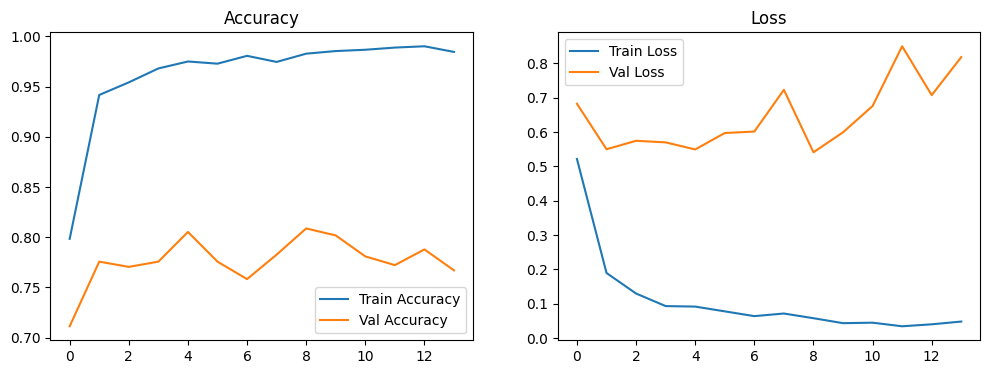

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()
plt.show()

In [ ]:
model.save("/content/drive/MyDrive/human_activity_model.h5")
print("Model saved to Google Drive! 📁")

Model saved to Google Drive! 📁


In [ ]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model


model_path = "/content/drive/MyDrive/human_activity_model.h5"
loaded_model = load_model(model_path)


def final_test(video_path):
    cap = cv2.VideoCapture(video_path)

    classes = ['Running', 'Standing', 'Walking']


    cap.set(cv2.CAP_PROP_POS_FRAMES, 30)
    ret, frame = cap.read()

    if ret:

        img = cv2.resize(frame, (128, 128))
        img = img / 255.0
        img = np.expand_dims(img, axis=0)


        prediction = loaded_model.predict(img, verbose=0)
        result = classes[np.argmax(prediction)]
        confidence = np.max(prediction) * 100

        print("-" * 30)
        print(f"VIDEO ANALYSIS RESULT:")
        print(f"File: {video_path.split('/')[-1]}")
        print(f"Human State: {result}")
        print(f"Confidence: {confidence:.2f}%")
        print("-" * 30)
    else:
        print(f"Error: {video_path}")
    cap.release()


my_video = "/content/drive/MyDrive/train.mp4"
final_test(my_video)

------------------------------
VIDEO ANALYSIS RESULT:
File: train.mp4
Human State: Standing
Confidence: 64.00%
------------------------------
